In [1]:
from pathlib import Path
from datetime import datetime, timezone
from time import perf_counter
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import Ridge
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

proyecto = Path.cwd()
if proyecto.name == "notebooks":
    proyecto = proyecto.parent

ruta = proyecto / "data" / "processed" / "wanliu_24h_preparado.csv.gz"
if not ruta.exists():
    raise FileNotFoundError("Ejecuta primero el notebook 02")

datos = pd.read_csv(ruta, parse_dates=["observed_at"])
train_completo = datos[datos["conjunto"] == "train"].reset_index(drop=True)
val = datos[datos["conjunto"] == "val"].reset_index(drop=True)
test = datos[datos["conjunto"] == "test"].reset_index(drop=True)

train = train_completo.copy()

print("Orígenes train disponibles:", len(train_completo))
print("Orígenes usados para entrenar:", len(train))
print("Orígenes val y test:", len(val), len(test))


Orígenes train disponibles: 21956
Orígenes usados para entrenar: 21956
Orígenes val y test: 4511 4641


In [2]:
ambientales = ["pm25", "pm10", "so2", "no2", "co", "o3", "temp", "pres", "dewp", "rain", "wspm"]
calendario = ["hora", "mes", "dia_semana", "horizonte", "hora_objetivo", "mes_objetivo", "dia_semana_objetivo", "hora_sin", "hora_cos", "mes_sin", "mes_cos"]

historia_24 = [f"pm25_hist_{h:02d}" for h in range(1, 24)]
historia_24 += ["pm25_media_6", "pm25_media_12", "pm25_media_24", "pm25_cuenta_24", "pm25_std_24", "temp_lag_1", "pm10_lag_1"]
historia_48 = historia_24 + ["pm25_hist_24", "pm25_hist_36", "pm25_hist_47", "pm25_media_48", "pm25_cuenta_48", "pm25_std_48", "temp_lag_24", "pm10_lag_24"]

variables_24 = ambientales + calendario + historia_24 + ["pm25_ayer", "wd"]
variables_48 = ambientales + calendario + historia_48 + ["pm25_ayer", "wd"]

columnas_base = ambientales + ["wd", "hora", "mes", "dia_semana"] + historia_48

def crear_ejemplos(tabla):
    partes = []
    for h in range(1, 25):
        parte = tabla[columnas_base].copy()
        parte["fecha_origen"] = tabla["observed_at"]
        parte["horizonte"] = h
        fecha_futura = tabla["observed_at"] + pd.Timedelta(hours=h)
        parte["hora_objetivo"] = fecha_futura.dt.hour
        parte["mes_objetivo"] = fecha_futura.dt.month
        parte["dia_semana_objetivo"] = fecha_futura.dt.day_of_week
        parte["hora_sin"] = np.sin(2 * np.pi * parte["hora_objetivo"] / 24)
        parte["hora_cos"] = np.cos(2 * np.pi * parte["hora_objetivo"] / 24)
        parte["mes_sin"] = np.sin(2 * np.pi * (parte["mes_objetivo"] - 1) / 12)
        parte["mes_cos"] = np.cos(2 * np.pi * (parte["mes_objetivo"] - 1) / 12)
        parte["pm25_ayer"] = tabla[f"pm25_hist_{24 - h:02d}"]
        parte["objetivo"] = tabla[f"y_{h:02d}"]
        parte["persistencia"] = tabla["pm25"]
        parte["ayer"] = parte["pm25_ayer"].fillna(parte["persistencia"])
        partes.append(parte)
    return pd.concat(partes, ignore_index=True)

train_largo = crear_ejemplos(train)
val_largo = crear_ejemplos(val)
test_largo = crear_ejemplos(test)

print("Ejemplos train / val / test:", len(train_largo), len(val_largo), len(test_largo))
display(train_largo[["fecha_origen", "horizonte", "pm25", "objetivo"]].head())

Ejemplos train / val / test: 526944 108264 111384


,fecha_origen,horizonte,pm25,objetivo
0,2013-03-02 23:00:00,1,84.0,88.0
1,2013-03-03 00:00:00,1,88.0,104.0
2,2013-03-03 01:00:00,1,104.0,106.0
3,2013-03-03 02:00:00,1,106.0,96.0
4,2013-03-03 03:00:00,1,96.0,89.0


In [10]:

def evaluar(real, predicho):
    predicho = np.maximum(predicho, 0)
    mae = mean_absolute_error(real, predicho)
    rmse = np.sqrt(mean_squared_error(real, predicho))
    r2 = r2_score(real, predicho)
    return {"MAE": mae, "RMSE": rmse, "R2": r2}


resultados = []
y_val = val_largo["objetivo"]

for nombre in ["persistencia", "ayer"]:
    valores = evaluar(y_val, val_largo[nombre])
    resultados.append({
        "Modelo": nombre,
        "Ventana": "-",
        **valores
    })

print("Resultados generales de validación")
display(pd.DataFrame(resultados).round(3))


filas = []

for h in range(1, 25):
    datos_hora = val_largo[val_largo["horizonte"] == h]
    reales = datos_hora["objetivo"]

    persistencia = evaluar(reales, datos_hora["persistencia"])
    ayer = evaluar(reales, datos_hora["ayer"])

    filas.append({
        "Horizonte": h,
        "MAE persistencia": persistencia["MAE"],
        "RMSE persistencia": persistencia["RMSE"],
        "MAE ayer": ayer["MAE"],
        "RMSE ayer": ayer["RMSE"]
    })

tabla_horizontes = pd.DataFrame(filas)

print("Errores de las referencias para cada hora futura")
display(tabla_horizontes.round(3))


fecha = val_largo["fecha_origen"].iloc[-1]

ejemplo = val_largo[
    val_largo["fecha_origen"] == fecha
].copy()

ejemplo = ejemplo.sort_values("horizonte")

ejemplo["fecha_futura"] = (
    ejemplo["fecha_origen"]
    + pd.to_timedelta(ejemplo["horizonte"], unit="h")
)

tabla_ejemplo = ejemplo[
    ["horizonte", "fecha_futura", "objetivo",
     "persistencia", "ayer"]
].copy()

tabla_ejemplo.columns = [
    "Horizonte", "Fecha futura", "PM2.5 real",
    "Persistencia", "Ayer"
]

print("Ejemplo completo de 24 horas")
display(tabla_ejemplo.round(2))


Resultados generales de validación


,Modelo,Ventana,MAE,RMSE,R2
0,persistencia,-,38.458,68.564,0.264
1,ayer,-,53.918,89.690,-0.260


Errores de las referencias para cada hora futura


,Horizonte,MAE persistencia,RMSE persistencia,MAE ayer,RMSE ayer
0,1,9.973,20.369,54.217,92.610
1,2,15.667,31.784,54.175,92.282
2,3,20.059,38.746,54.061,91.292
3,4,23.709,45.425,53.957,90.897
4,5,26.714,50.303,53.857,90.300
5,6,29.241,54.294,53.715,89.607
6,7,31.501,57.556,53.594,89.060
7,8,33.249,60.044,53.492,88.714
8,9,35.006,62.432,53.413,88.599
9,10,36.725,64.802,53.402,88.501


Ejemplo completo de 24 horas


C:\Users\PC\AppData\Local\Temp\ipykernel_5484\3906842800.py:71: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  display(tabla_ejemplo.round(2))


,Horizonte,Fecha futura,PM2.5 real,Persistencia,Ayer
4510,1,2016-07-23 20:00:00,177.0,180.0,55.0
9021,2,2016-07-23 21:00:00,125.0,180.0,72.0
13532,3,2016-07-23 22:00:00,46.0,180.0,104.0
18043,4,2016-07-23 23:00:00,50.0,180.0,120.0
22554,5,2016-07-24 00:00:00,59.0,180.0,135.0
27065,6,2016-07-24 01:00:00,54.0,180.0,145.0
31576,7,2016-07-24 02:00:00,49.0,180.0,153.0
36087,8,2016-07-24 03:00:00,52.0,180.0,161.0
40598,9,2016-07-24 04:00:00,59.0,180.0,153.0
45109,10,2016-07-24 05:00:00,54.0,180.0,149.0


In [4]:

variables_compactas = [
    "pm25", "pm10", "so2", "no2", "co", "o3",
    "temp", "pres", "dewp", "rain", "wspm", "wd",
    "horizonte", "hora_sin", "hora_cos", "mes_sin", "mes_cos",
    "pm25_hist_08", "pm25_hist_12", "pm25_hist_13",
    "pm25_hist_14", "pm25_hist_23",
    "pm25_media_6", "pm25_media_12", "pm25_media_24",
    "pm25_cuenta_24", "pm25_std_24", "temp_lag_1", "pm25_ayer"
]

for variables in [variables_24, variables_compactas]:
    assert len(variables) == len(set(variables))
    assert set(variables).issubset(train_largo.columns)

print("Variables completas:", len(variables_24))
print("Variables compactas:", len(variables_compactas))


def crear_pipeline(algoritmo, variables, parametros=None):
    numericas = [col for col in variables if col != "wd"]

    if algoritmo == "Ridge":
        pasos_numericos = Pipeline([
            ("imputacion", SimpleImputer(strategy="median")),
            ("escalado", StandardScaler())
        ])
        regresor = Ridge(alpha=100, solver="lsqr")

    else:
        pasos_numericos = SimpleImputer(strategy="median")
        regresor = HistGradientBoostingRegressor(
            **parametros,
            l2_regularization=1.0,
            early_stopping=False,
            random_state=42
        )

    preparacion = ColumnTransformer([
        ("numericas", pasos_numericos, numericas),
        ("viento", OneHotEncoder(
            handle_unknown="ignore",
            sparse_output=False
        ), ["wd"])
    ])

    return Pipeline([
        ("preparacion", preparacion),
        ("modelo", regresor)
    ])


parametros_actuales = {
    "max_iter": 80,
    "learning_rate": 0.08,
    "max_leaf_nodes": 25
}

parametros_1 = {
    "max_iter": 120,
    "learning_rate": 0.06,
    "max_leaf_nodes": 31
}

parametros_2 = {
    "max_iter": 150,
    "learning_rate": 0.05,
    "max_leaf_nodes": 15
}

parametros_3 = {
    "max_iter": 200,
    "learning_rate": 0.04,
    "max_leaf_nodes": 31
}


experimentos = [
    ("Ridge_24h_completo",
     "Ridge", variables_24, "completo", None),

    ("HistGradientBoosting_24h_completo",
     "HistGradientBoosting", variables_24,
     "completo", parametros_actuales),

    ("HistGradientBoosting_24h_compacto_actual",
     "HistGradientBoosting", variables_compactas,
     "compacto", parametros_actuales),

    ("HistGradientBoosting_24h_compacto_1",
     "HistGradientBoosting", variables_compactas,
     "compacto", parametros_1),

    ("HistGradientBoosting_24h_compacto_2",
     "HistGradientBoosting", variables_compactas,
     "compacto", parametros_2),

    ("HistGradientBoosting_24h_compacto_3",
     "HistGradientBoosting", variables_compactas,
     "compacto", parametros_3)
]


indices = np.linspace(
    0, len(train_largo) - 1,
    min(12000, len(train_largo))
).astype(int)

train_muestra = train_largo.iloc[indices]

resultados = [
    r for r in resultados
    if r["Modelo"] in ["persistencia", "ayer"]
]

modelos = {}

for nombre, algoritmo, variables, grupo, parametros in experimentos:
    print("Entrenando:", nombre)

    inicio = perf_counter()

    modelo = crear_pipeline(algoritmo, variables, parametros)

    modelo.fit(
        train_largo[variables],
        train_largo["objetivo"]
    )

    pred_val = np.maximum(
        0, modelo.predict(val_largo[variables])
    )

    pred_train = np.maximum(
        0, modelo.predict(train_muestra[variables])
    )

    metricas = evaluar(y_val, pred_val)

    mae_train = mean_absolute_error(
        train_muestra["objetivo"], pred_train
    )

    duracion = perf_counter() - inicio

    resultados.append({
        "Modelo": nombre,
        "Ventana": 24,
        "Grupo": grupo,
        "Variables": len(variables),
        "MAE_train_muestra": mae_train,
        "Segundos": round(duracion, 1),
        **metricas
    })

    modelos[nombre] = {
        "modelo": modelo,
        "variables": variables,
        "ventana": 24,
        "grupo": grupo,
        "metricas": metricas
    }

    print("MAE:", round(metricas["MAE"], 3))
    print("RMSE:", round(metricas["RMSE"], 3))
    print("Tiempo:", round(duracion, 1), "segundos")


tabla = pd.DataFrame(resultados).sort_values(
    ["MAE", "RMSE"]
)

display(tabla.round(3))


Variables completas: 54
Variables compactas: 29
Entrenando: Ridge_24h_completo
MAE: 39.089
RMSE: 59.941
Tiempo: 5.8 segundos
Entrenando: HistGradientBoosting_24h_completo
MAE: 35.729
RMSE: 55.189
Tiempo: 6.5 segundos
Entrenando: HistGradientBoosting_24h_compacto_actual
MAE: 35.6
RMSE: 55.058
Tiempo: 3.8 segundos
Entrenando: HistGradientBoosting_24h_compacto_1
MAE: 35.708
RMSE: 55.146
Tiempo: 5.3 segundos
Entrenando: HistGradientBoosting_24h_compacto_2
MAE: 36.056
RMSE: 55.808
Tiempo: 5.2 segundos
Entrenando: HistGradientBoosting_24h_compacto_3
MAE: 35.847
RMSE: 55.062
Tiempo: 7.4 segundos


,Modelo,Ventana,MAE,RMSE,R2,Grupo,Variables,MAE_train_muestra,Segundos
4,HistGradientBoosting_24h_compacto_actual,24,35.600,55.058,0.525,compacto,29.0,34.064,3.8
5,HistGradientBoosting_24h_compacto_1,24,35.708,55.146,0.524,compacto,29.0,32.702,5.3
3,HistGradientBoosting_24h_completo,24,35.729,55.189,0.523,completo,54.0,33.625,6.5
7,HistGradientBoosting_24h_compacto_3,24,35.847,55.062,0.525,compacto,29.0,32.316,7.4
6,HistGradientBoosting_24h_compacto_2,24,36.056,55.808,0.512,compacto,29.0,35.736,5.2
0,persistencia,-,38.458,68.564,0.264,NaN,NaN,NaN,NaN
2,Ridge_24h_completo,24,39.089,59.941,0.437,completo,54.0,41.046,5.8
1,ayer,-,53.918,89.690,-0.260,NaN,NaN,NaN,NaN


In [5]:
referencias = tabla[tabla["Modelo"].isin(["persistencia", "ayer"])].sort_values("MAE")
mejor_referencia = referencias.iloc[0]
candidatos = tabla[~tabla["Modelo"].isin(["persistencia", "ayer"])].sort_values(["MAE", "RMSE"])
mejor_nombre = candidatos.iloc[0]["Modelo"]
seleccionado = modelos[mejor_nombre]

mejora = (1 - seleccionado["metricas"]["MAE"] / mejor_referencia["MAE"]) * 100
cumple_mae = mejora >= 10
cumple_rmse = seleccionado["metricas"]["RMSE"] <= mejor_referencia["RMSE"]

print("Modelo seleccionado:", mejor_nombre)
print("Variables del modelo:", len(seleccionado["variables"]))
print("Grupo de variables:", seleccionado["grupo"])
print("Mejora de MAE frente a la referencia:", round(mejora, 2), "%")
print("Meta provisional de mejora MAE >=10%:", cumple_mae)
print("RMSE no empeora:", cumple_rmse)
if not cumple_mae or not cumple_rmse:
    print("La meta provisional aún no está cumplida.")


Modelo seleccionado: HistGradientBoosting_24h_compacto_actual
Variables del modelo: 29
Grupo de variables: compacto
Mejora de MAE frente a la referencia: 7.43 %
Meta provisional de mejora MAE >=10%: False
RMSE no empeora: True
La meta provisional aún no está cumplida.


In [6]:
variables_elegidas = seleccionado["variables"]
X_test = test_largo[variables_elegidas]
y_test = test_largo["objetivo"]
pred_test = np.maximum(0, seleccionado["modelo"].predict(X_test))

resultados_test = []
for nombre in ["persistencia", "ayer"]:
    resultados_test.append({"Modelo": nombre, **evaluar(y_test, test_largo[nombre])})
resultados_test.append({"Modelo": mejor_nombre, **evaluar(y_test, pred_test)})
display(pd.DataFrame(resultados_test).round(3))

filas = []
for comienzo in [1, 7, 13, 19]:
    mascara = test_largo["horizonte"].between(comienzo, comienzo + 5)
    m = evaluar(y_test[mascara], pred_test[mascara])
    filas.append({"Bloque": f"+{comienzo} a +{comienzo + 5}", **m})
resultado_bloques = pd.DataFrame(filas)
display(resultado_bloques.round(3))

por_horizonte = []
for h in range(1, 25):
    mascara = test_largo["horizonte"] == h
    mae = mean_absolute_error(y_test[mascara], pred_test[mascara])
    por_horizonte.append(mae)

display(pd.DataFrame({"Horizonte": range(1, 25), "MAE": por_horizonte}).round(3))

,Modelo,MAE,RMSE,R2
0,persistencia,45.339,75.770,0.332
1,ayer,65.235,97.574,-0.108
2,HistGradientBoosting_24h_compacto_actual,42.849,68.753,0.450


,Bloque,MAE,RMSE,R2
0,+1 a +6,26.181,45.242,0.762
1,+7 a +12,40.599,66.146,0.492
2,+13 a +18,49.271,76.122,0.326
3,+19 a +24,55.347,81.799,0.219


,Horizonte,MAE
0,1,17.861
1,2,21.508
2,3,24.724
3,4,27.914
4,5,31.116
5,6,33.961
6,7,36.248
7,8,38.180
8,9,40.067
9,10,41.445


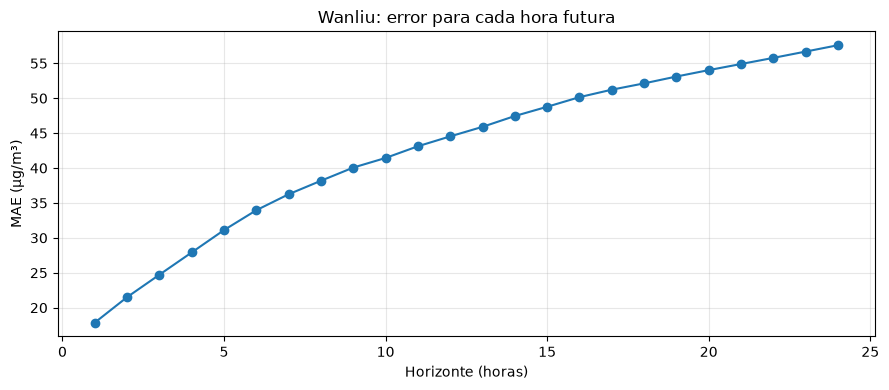

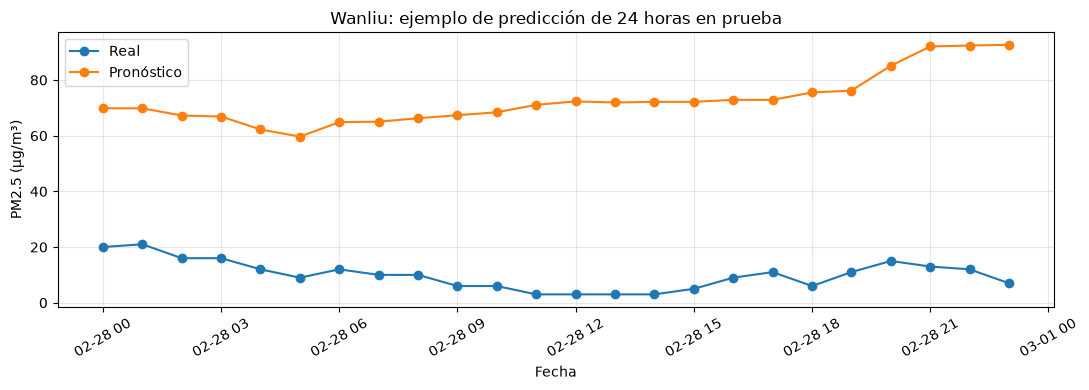

In [7]:
plt.figure(figsize=(9, 4))
plt.plot(range(1, 25), por_horizonte, marker="o")
plt.title("Wanliu: error para cada hora futura")
plt.xlabel("Horizonte (horas)")
plt.ylabel("MAE (µg/m³)")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

ultima_fecha = test["observed_at"].iloc[-1]
mascara = test_largo["fecha_origen"] == ultima_fecha
ejemplo = test_largo[mascara].copy()
ejemplo["predicho"] = pred_test[mascara.to_numpy()]
fechas_futuras = ejemplo["fecha_origen"] + pd.to_timedelta(ejemplo["horizonte"], unit="h")

plt.figure(figsize=(11, 4))
plt.plot(fechas_futuras, ejemplo["objetivo"], label="Real", marker="o")
plt.plot(fechas_futuras, ejemplo["predicho"], label="Pronóstico", marker="o")
plt.title("Wanliu: ejemplo de predicción de 24 horas en prueba")
plt.xlabel("Fecha")
plt.ylabel("PM2.5 (µg/m³)")
plt.grid(alpha=0.3)
plt.legend()
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

,Variable,Incremento_MAE
0,pm25,16.827
3,no2,1.724
12,horizonte,1.419
26,pm25_std_24,1.070
8,dewp,0.924
10,wspm,0.905
16,mes_cos,0.753
6,temp,0.711
24,pm25_media_24,0.621
14,hora_cos,0.596


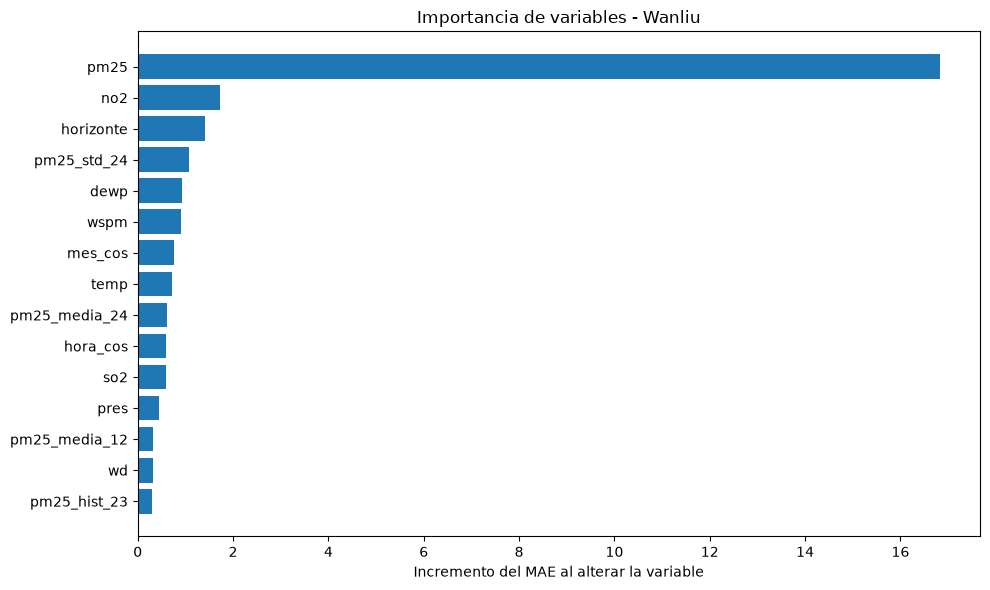

In [8]:
from sklearn.inspection import permutation_importance

indices = np.linspace(0, len(val) - 1, min(120, len(val))).astype(int)
fechas = val.iloc[indices]["observed_at"]
muestra = val_largo[val_largo["fecha_origen"].isin(fechas)]

X = muestra[variables_elegidas]
y = muestra["objetivo"]

importancia = permutation_importance(
    seleccionado["modelo"],
    X,
    y,
    scoring="neg_mean_absolute_error",
    n_repeats=2,
    random_state=42,
    n_jobs=1
)

tabla_importancia = pd.DataFrame({
    "Variable": X.columns,
    "Incremento_MAE": importancia.importances_mean
}).sort_values("Incremento_MAE", ascending=False)

display(tabla_importancia.round(3))

principales = tabla_importancia.head(15).sort_values("Incremento_MAE")
plt.figure(figsize=(10, 6))
plt.barh(principales["Variable"], principales["Incremento_MAE"])
plt.xlabel("Incremento del MAE al alterar la variable")
plt.title("Importancia de variables - Wanliu")
plt.tight_layout()
plt.show()


In [9]:
archivo = proyecto / "models" / "wanliu_pm25_24h.joblib"
archivo.parent.mkdir(parents=True, exist_ok=True)

paquete = {
    "version": "wanliu-direct-24h-v3",
    "station": "Wanliu",
    "model": seleccionado["modelo"],
    "model_name": mejor_nombre,
    "feature_columns": variables_elegidas,
    "feature_group": seleccionado["grupo"],
    "history_window_hours": seleccionado["ventana"],
    "validation_metrics": seleccionado["metricas"],
    "test_metrics": evaluar(y_test, pred_test),
    "test_metrics_6h": resultado_bloques.to_dict(orient="records"),
    "candidate_validation_results": tabla.to_dict(orient="records"),
    "meets_provisional_target": bool(cumple_mae and cumple_rmse),
    "trained_at_utc": datetime.now(timezone.utc).isoformat(),
    "training_data_last_origin": str(train["observed_at"].max()),
    "horizons": list(range(1, 25)),
    "clip_min": 0.0
}
joblib.dump(paquete, archivo)
print("Modelo guardado:", archivo)
print("Algoritmo:", mejor_nombre)
print("Cantidad de variables:", len(variables_elegidas))
print("La API deberá generar estas mismas variables de entrada.")


Modelo guardado: c:\Users\PC\Proyectos\beijing-pm25-crisp-mlq\models\wanliu_pm25_24h.joblib
Algoritmo: HistGradientBoosting_24h_compacto_actual
Cantidad de variables: 29
La API deberá generar estas mismas variables de entrada.
